# Examination of a 1D Powered Rocket Ascent w/ Drag

## 1. Governing Initial Value Problem (IVP)

To characterize aerodynamic drag losses on a sounding rocket during powered vertical flight, we model the rocket as a 1D point mass ascending through an exponential atmosphere under constant motor thrust $T$ and constant gravitational acceleration $g$. 

### State Vector & Coupled ODE System
Let $h(t)$ be the altitude, $v(t)$ be the vertical velocity, $m(t)$ be the instantaneous rocket mass, and $\Delta v_{\text{drag}}(t)$ be the cumulative velocity loss due to aerodynamic drag. Over the powered burn duration $t \in [0, t_b]$, the state vector $y(t)$ and its time derivative $\dot{y} = f(t, y)$ are governed by the non-autonomous nonlinear system:

$$y(t) = \begin{bmatrix} h(t) \\ v(t) \\ m(t) \\ \Delta v_{\text{drag}}(t) \end{bmatrix}, \qquad \frac{dy}{dt} = f(t, y) = \begin{bmatrix} v \\[6pt] \dfrac{T}{m} - g - \dfrac{\rho(h) C_D S}{2m} v|v| \\[8pt] -\dfrac{T}{I_{sp} g} \\[8pt] \dfrac{\rho(h) C_D S}{2m} v^2 \end{bmatrix}$$

### Initial Conditions & Time Domain
Assuming the rocket launches vertically from rest at sea level at $t = 0$:

$$h(0) = 0\text{ m}, \qquad v(0) = 0\text{ m/s}, \qquad m(0) = m_0, \qquad \Delta v_{\text{drag}}(0) = 0\text{ m/s}$$

The integration domain spans the powered burn phase $t \in [0, t_b]$, where burnout occurs when all propellant is expended ($m(t_b) = m_{\text{dry}}$):

$$t_b = \frac{(m_0 - m_{\text{dry}}) I_{sp} g}{T}$$

### Supporting Models
* **Exponential Atmosphere:** Air density decays exponentially with altitude $h$ according to scale height $H$:
  $$\rho(h) = \rho_0 e^{-h/H}$$
* **Cross-Sectional Reference Area:** For a cylindrical rocket body of diameter $d$:
  $$S = \frac{\pi d^2}{4}$$
* **Propellant Mass Flow Rate:** Constant mass consumption rate during motor burn:
  $$\dot{m} = -\frac{T}{I_{sp} g}$$

---

## 2. Nominal System Parameters

| Parameter | Symbol | Value | Units |
| :--- | :---: | :---: | :---: |
| Gravitational Acceleration | $g$ | $9.81$ | $\text{m/s}^2$ |
| Sea-Level Air Density | $\rho_0$ | $1.225$ | $\text{kg/m}^3$ |
| Atmospheric Scale Height | $H$ | $8500$ | $\text{m}$ |
| Liftoff (Wet) Mass | $m_0$ | $50.0$ | $\text{kg}$ |
| Burnout (Dry) Mass | $m_{\text{dry}}$ | $20.0$ | $\text{kg}$ |
| Motor Thrust | $T$ | $3000.0$ | $\text{N}$ |
| Specific Impulse | $I_{sp}$ | $230.0$ | $\text{s}$ |
| Rocket Body Diameter | $d$ | $0.15$ | $\text{m}$ |
| Reference Area | $S$ | $0.01767$ | $\text{m}^2$ |
| Drag Coefficient | $C_D$ | $0.4$ | — |
| Mass Flow Rate | $\dot{m}$ | $1.3296$ | $\text{kg/s}$ |
| Burnout Time | $t_b$ | $22.563$ | $\text{s}$ |

## Implementing RK4

In [7]:
import numpy as np
import matplotlib.pyplot as plt


# parameters
g = 9.81
rho0 = 1.225
H = 8500

m0 = 50
m_dry = 20
T = 3000
Isp = 230
d = 0.15

# derived paramters
S = np.pi * d**2 / 4
mdot = T / (Isp * g)
t_b = (m0 - m_dry) / mdot


def rocket_burn_rhs(u, t, C_D):
    h, v, m, dv_drag = u

    rho_local = rho0 * np.exp(-h / H)
    drag_factor = (rho_local * C_D * S) / (2 * m)

    h_dot = v
    v_dot = (T / m) - g - drag_factor * v * abs(v)
    m_dot = -mdot
    dv_drag_dot = drag_factor * v**2

    return np.array([h_dot, v_dot, m_dot, dv_drag_dot], dtype=float)


def rk4_step(f, u_k, t_k, dt, C_D):
    y1 = f(u_k, t_k, C_D)
    y2 = f(u_k + 0.5 * dt * y1, t_k + 0.5 * dt, C_D)
    y3 = f(u_k + 0.5 * dt * y2, t_k + 0.5 * dt, C_D)
    y4 = f(u_k + dt * y3, t_k + dt, C_D)
    
    return u_k + (dt / 6) * (y1 + 2 * y2 + 2 * y3 + y4)


def solve_burn_ivp(n_steps, C_D):
    dt = t_b / n_steps
    t = np.linspace(0.0, t_b, n_steps + 1)
    u = np.zeros((n_steps + 1, 4), dtype=float)

    u[0] = np.array([0, 0, m0, 0])

    for k in range(n_steps):
        u[k + 1] = rk4_step(rocket_burn_rhs, u[k], t[k], dt, C_D)

    return t, u, dt

## Verifying the Convergence Rate and Accuracy

1. Analytical Special-Case Verification (C_D = 0)
Exact Burnout Altitude h(t_b) : 17313.581907 m
Exact Burnout Velocity v(t_b) : 1846.083748 m/s
Convergence Rate vs. Exact    : p = 3.9969

2. Full Nonlinear Model Convergence & Step Size Study (C_D = 0.4)
     N |    dt [s] |  Rel Err h(tb) |  Rel Err v(tb) | Rel Err dv_drag
--------------------------------------------------------------------
    10 |   2.25630 |     9.3646e-06 |     8.5937e-06 |      1.2165e-05
    20 |   1.12815 |     6.0091e-07 |     5.8288e-07 |      8.4156e-07
    40 |   0.56408 |     3.7793e-08 |     3.7470e-08 |      5.4470e-08
    80 |   0.28204 |     2.3675e-09 |     2.3656e-09 |      3.4602e-09
   160 |   0.14102 |     1.5000e-10 |     1.4573e-10 |      2.2561e-10
   320 |   0.07051 |     1.1362e-11 |     6.2792e-12 |      2.2157e-11
   640 |   0.03525 |     2.6965e-12 |     2.4569e-12 |      9.4025e-12
  1280 |   0.01763 |     2.1548e-12 |     3.0023e-12 |      8.6017e-12

Observed Full-Model Convergence Rate

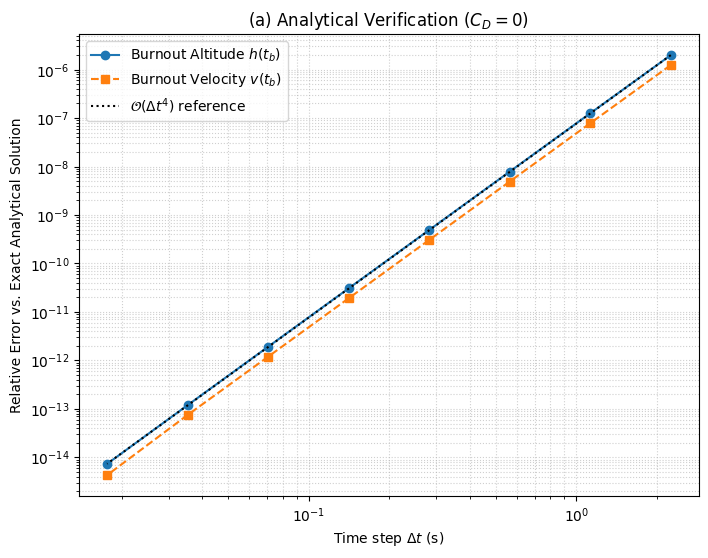

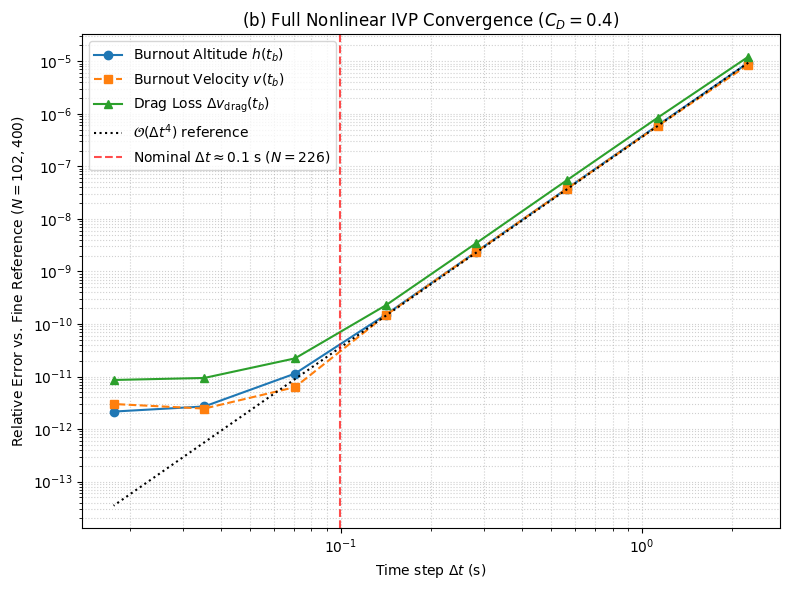

In [9]:
def exact_drag_free_solution(t):
    ve = Isp * g
    m_t = m0 - mdot * t

    v_exact = ve * np.log(m0 / m_t) - g * t
    h_exact = ve * (t + (m_t / mdot) * np.log(m_t / m0)) - 0.5 * g * (t ** 2)
    return h_exact, v_exact


ns = np.array([10, 20, 40, 80, 160, 320, 640, 1280])
dts = t_b / ns


# verify against exact solution (C_D = 0)
h_ex_tb, v_ex_tb = exact_drag_free_solution(t_b)
err_h_ideal = np.zeros(len(ns))
err_v_ideal = np.zeros(len(ns))

for i, n in enumerate(ns):
    t, u, dt = solve_burn_ivp(n, C_D=0.0)
    err_h_ideal[i] = abs(u[-1, 0] - h_ex_tb) / abs(h_ex_tb)
    err_v_ideal[i] = abs(u[-1, 1] - v_ex_tb) / abs(v_ex_tb)

rate_ideal = np.polyfit(np.log10(dts[:6]), np.log10(err_h_ideal[:6]), 1)[0]
print('1. Analytical Special-Case Verification (C_D = 0)')
print(f'Exact Burnout Altitude h(t_b) : {h_ex_tb:.6f} m')
print(f'Exact Burnout Velocity v(t_b) : {v_ex_tb:.6f} m/s')
print(f'Convergence Rate vs. Exact    : p = {rate_ideal:.4f}\n')


# show convergence and step size selection
t_ref, u_ref, dt_ref = solve_burn_ivp(n_steps=102400, C_D=0.4)
h_ref, v_ref, dv_ref = u_ref[-1, 0], u_ref[-1, 1], u_ref[-1, 3]

err_h_drag = np.zeros(len(ns))
err_v_drag = np.zeros(len(ns))
err_dv_drag = np.zeros(len(ns))

print('2. Full Nonlinear Model Convergence & Step Size Study (C_D = 0.4)')
print(f"{'N':>6} | {'dt [s]':>9} | {'Rel Err h(tb)':>14} | {'Rel Err v(tb)':>14} | {'Rel Err dv_drag':>15}")
print('-' * 68)

for i, n in enumerate(ns):
    t, u, dt = solve_burn_ivp(n, C_D=0.4)
    err_h_drag[i] = abs(u[-1, 0] - h_ref) / abs(h_ref)
    err_v_drag[i] = abs(u[-1, 1] - v_ref) / abs(v_ref)
    err_dv_drag[i] = abs(u[-1, 3] - dv_ref) / abs(dv_ref)

    print(f'{n:6d} | {dt:9.5f} | {err_h_drag[i]:14.4e} | {err_v_drag[i]:14.4e} | {err_dv_drag[i]:15.4e}')

rate_drag = np.polyfit(np.log10(dts[:6]), np.log10(err_h_drag[:6]), 1)[0]
print(f'\nObserved Full-Model Convergence Rate: p = {rate_drag:.4f}\n')


# momentum conservation identity check at dt = 0.1s
t_nom_0, u_nom_0, dt_nom_0 = solve_burn_ivp(n_steps=226, C_D=0.0)
t_nom_d, u_nom_d, dt_nom_d = solve_burn_ivp(n_steps=226, C_D=0.4)
dv_by_subtraction = u_nom_0[-1, 1] - u_nom_d[-1, 1]
dv_by_direct_state = u_nom_d[-1, 3]

print('3. Integral Momentum Conservation Check (at dt ~ 0.1 s)')
print(f'Drag loss via state subtraction (v_CD0 - v_CD0.4) : {dv_by_subtraction:.10f} m/s')
print(f'Drag loss via 4th state integral (dv_drag)        : {dv_by_direct_state:.10f} m/s')
print(f'Discrepancy between methods                       : {abs(dv_by_subtraction - dv_by_direct_state):.3e} m/s')


# plotting
fig, ax1 = plt.subplots(1, 1, figsize=(8,6))

# Left panel: Exact Analytical Verification (C_D = 0)
ax1.loglog(dts, err_h_ideal, 'o-', label=r'Burnout Altitude $h(t_b)$')
ax1.loglog(dts, err_v_ideal, 's--', label=r'Burnout Velocity $v(t_b)$')
ax1.loglog(dts, err_h_ideal[0] * (dts / dts[0])**4, 'k:', label=r'$\mathcal{O}(\Delta t^4)$ reference')
ax1.set_xlabel(r'Time step $\Delta t$ (s)')
ax1.set_ylabel('Relative Error vs. Exact Analytical Solution')
ax1.set_title(r'(a) Analytical Verification ($C_D = 0$)')
ax1.grid(True, which='both', ls=':', alpha=0.6)
ax1.legend()

fig, ax2 = plt.subplots(1, 1, figsize=(8,6))

# Right panel: Full Nonlinear Drag Model Self-Convergence (C_D = 0.4)
ax2.loglog(dts, err_h_drag, 'o-', label=r'Burnout Altitude $h(t_b)$')
ax2.loglog(dts, err_v_drag, 's--', label=r'Burnout Velocity $v(t_b)$')
ax2.loglog(dts, err_dv_drag, '^-', label=r'Drag Loss $\Delta v_{\mathrm{drag}}(t_b)$')
ax2.loglog(dts, err_h_drag[0] * (dts / dts[0])**4, 'k:', label=r'$\mathcal{O}(\Delta t^4)$ reference')
ax2.axvline(t_b / 226, color='r', ls='--', alpha=0.7, label=r'Nominal $\Delta t \approx 0.1$ s ($N=226$)')
ax2.set_xlabel(r'Time step $\Delta t$ (s)')
ax2.set_ylabel('Relative Error vs. Fine Reference ($N=102,400$)')
ax2.set_title(r'(b) Full Nonlinear IVP Convergence ($C_D = 0.4$)')
ax2.grid(True, which='both', ls=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()